<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Transactions_Pass_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Collection/Sources


#### Description
Data source is transaction data in a 'csv' file from AWS S3. It contains nulls and identifier columns. Some 'var_x' feature columns contain all nulls. The target is binary (0 = unsuccessful, 1 = successful) its proportions are unbalanced. The full data set is used at the start (no row/column range constraints).

### Load Modules

In [7]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

import requests

from google.colab import userdata
import os

### Authenticate to Hugging Face


In [8]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [9]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [10]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [11]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [12]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/transactions.parquet'

In [13]:
df3 = pd.read_parquet( hf_url )
df3.shape


(180000, 51)

In [14]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   target  180000 non-null  float64
 1   var_0   180000 non-null  float64
 2   var_1   180000 non-null  float64
 3   var_2   180000 non-null  float64
 4   var_4   180000 non-null  float64
dtypes: float64(5)
memory usage: 6.9 MB


In [15]:
X_features = df3.drop(columns=['target']).copy()
X_features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,0.5878,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
1,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,6.5456,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
2,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,18.7893,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
3,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,1.1400,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
4,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,7.8002,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,3.1549,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
179996,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,3.9661,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
179997,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,3.8858,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
179998,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,2.0014,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [16]:
y_target = df3['target'].copy()
y_target

,target
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
179995,0.0
179996,0.0
179997,1.0
179998,0.0


## Backup

In [17]:
df = df3.copy()

# Random Forest Classification

## Max Depth = 3

In [18]:
numLoops = 10
acc_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = RandomForestClassifier(max_depth=3)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc_scores[idx] = accuracy_score(y_test, y_pred)

print(f"Mean CV Accuracy: {acc_scores.mean():.4f}")


Mean CV Accuracy: 0.8999


## Choose Best Max Depth

In [19]:
max_depths = range(1, 3)
cv_loops = 10
acc_results = np.zeros(len(max_depths))
std_results = np.zeros(len(max_depths))

for n, depth in enumerate(max_depths):
  acc_cv = np.zeros(cv_loops)
  np.random.seed(42)
  for i in range(cv_loops):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.20)
    rfModel = RandomForestClassifier(max_depth=depth)
    rfModel.fit(X_train, y_train)
    y_pred_rf = rfModel.predict(X_test)
    acc_cv[i] = accuracy_score(y_test, y_pred_rf)
  print(depth, 'max_depth finished.')
  acc_results[n] = acc_cv.mean()
  std_results[n] = acc_cv.std()


1 max_depth finished.
2 max_depth finished.


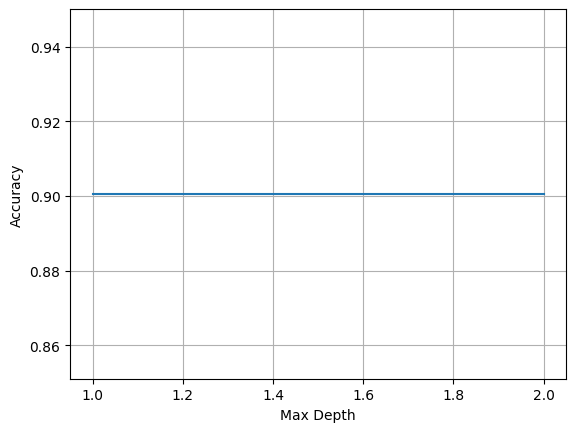

In [20]:
plt.plot(max_depths, acc_results)
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.grid()

In [21]:
pd.DataFrame(zip(max_depths, acc_results, std_results), columns="depth Accuracy STDev".split())

,depth,Accuracy,STDev
0,1,0.900569,0.000986
1,2,0.900569,0.000986


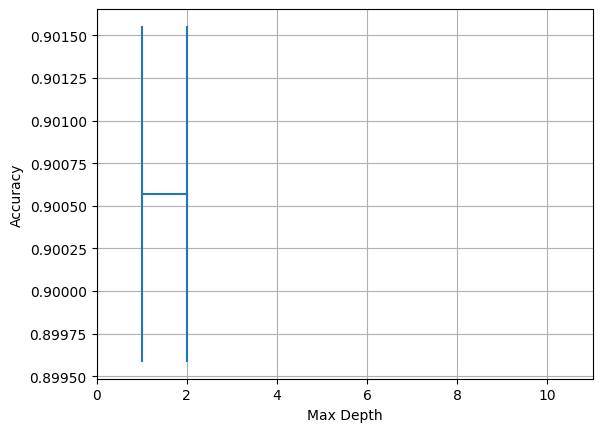

In [22]:
# plt.errorbar(num_trees, rmse_results, yerr=(std_results*2,std_results*2))
plt.errorbar(max_depths, acc_results, yerr=std_results)
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.xlim(0, 11)
plt.grid()

In [23]:
# Best depth result
best_depth = max_depths[np.argmax(acc_results)]
print(f'Best Max Depth: {best_depth} (Accuracy: {acc_results.max():.4f})')

Best Max Depth: 1 (Accuracy: 0.9006)


## Max Depth = Best

In [24]:
numLoops = 10
acc_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = RandomForestClassifier(max_depth=best_depth)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc_scores[idx] = accuracy_score(y_test, y_pred)

print(f"Mean CV Accuracy: {acc_scores.mean():.4f}")


Mean CV Accuracy: 0.8999


# Visualize the Tree

In [25]:
import graphviz
from IPython.display import display
from sklearn import tree


In [26]:
# Display one tree from the random forest
display(
  graphviz.Source(
    tree.export_graphviz(
      model.estimators_[0],
      feature_names = X.columns,
    )
  )
)


NameError: name 'X' is not defined

## Find Important Predictors

In [ ]:
importances = model.feature_importances_
forest_importances = pd.Series( importances, index = X.columns )

plt.figure()
# forest_importances.plot.bar()
forest_importances.sort_values( ascending = True ).plot.barh()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;


In [ ]:
( forest_importances.sort_values( ascending = False ) * 100 ).cumsum()
